**STAGE 1**

**Guess**
- Guess 1: median sale price                          ~ 153000
- Guess 2: how many of the 81 columns have missing    ~ 5
- Guess 3: the single column that predicts price best ~ house_price
- Guess 4: the error of a good model, as a percentage ~ 15 %
- Guess 5: cheapest-median or dearest-median neighbourhood? dearest-median

- S1-1  One row of this file = one sold house .
- S1-2  The target is called SalePrice . It is a continuous number, so this is
    regression (classification / regression).
- S1-3  The baseline model is  DummyRegressor(strategy="mean") . It predicts
    the standard deviation of the training targets for every house. Its RMSE comes out
    roughly equal to the MEAN of the target.
- S1-4  RMSE punishes big mistakes more than small ones because the errors are
    squared before they are averaged.
- S1-5  My PRIMARY metric is RMSE on the log of the price, because
    prices are right-skewed (T2). My SECOND metric is MAE in dollars, because a manager
    can understand it. R2 is a third, optional view.
- S1-6  The mistake that costs more for a valuation firm: Under-valuing (over- or
    under-valuing) because if the model predicts the price too low, then it will miss to capture the true value . (There is no single right answer; defend
    yours in one sentence.)

**One row is one sold house in Ames. The target is SalePrice. The decision is to estimate a house’s sale price for the real-estate firm. The worse mistake is under-valuing, because the seller loses money and the firm loses trust. My metrics are RMSE on the log price, MAE in dollars, and R2 as an optional third view.**



**STAGE 2 - LOAD THE FILE**
- QUESTION: what does this file look like, and does the loader change it?
    * The file has 1,460 houses and 81 columns (38 numeric, 43 text). The first row is a house, not a header. The loader changes it: pandas turns the text ‘NA’ and ‘None’ into NaN, so a blank can mean ‘no feature’ and not ‘unknown’.

- S2-1  Shape = 1460 rows x 81 columns. Numeric columns: 38 . Text
      columns: 43 . (read them from your output; Id and SalePrice are inside
      the numeric count)
- S2-2  The method that prints each column's type and non-null count is
      df.info() .
- S2-3  By default pandas turns the text "NA" into a NaN value. I switch it
      off with  read_csv(path, keep_default_na=False) . With it off, the
      Alley column contains the text "NA" in 1369 rows.
-  S2-4  MasVnrType: missing count in read 1 = 872 ; in read 2 the text
      "None" appears 864 times and the text "NA" 8 times. So the real
      unknowns are 8 rows and the other 864 rows are houses with no
      veneer.
- S2-5  MSSubClass is stored as int64 but behaves like a category (it is a code).
      I will convert it to string before encoding.
-  S2-6  Id has 1460 unique values. I drop it because it has no information to predict .
-  S2-7  OverallQual runs from 1 to 10 . It is an ordinal(ordered) rating
      stored as a number. A tree can use it directly; a linear model assumes
      each step adds the same dollars, which is only roughly true.

**Decision**
- The raw read tell me what the file really says. In text columns, "NA" means the house has no feature. Only a few values are truly unknown. But I will model from the default df, not from raw. In raw, the numeric column LotFrontage contains the text “NA” and would become a text column, which breaks the numbers.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("train.csv")
print(df.shape)

(1460, 81)


In [3]:
#print(df.head(5))
print(df.sample(5, random_state=42))

        Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
892    893          20       RL         70.0     8414   Pave   NaN      Reg   
1105  1106          60       RL         98.0    12256   Pave   NaN      IR1   
413    414          30       RM         56.0     8960   Pave  Grvl      Reg   
522    523          50       RM         50.0     5000   Pave   NaN      Reg   
1036  1037          20       RL         89.0    12898   Pave   NaN      IR1   

     LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
892          Lvl    AllPub  ...        0    NaN  MnPrv         NaN       0   
1105         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
413          Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
522          Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
1036         HLS    AllPub  ...        0    NaN    NaN         NaN       0   

     MoSold YrSold  SaleType  SaleCondition  SalePrice  

In [4]:
#print(df.dtypes)
print(df.info())
print(df["MasVnrType"].isna().sum())
print(df.select_dtypes(include="number").shape[1])
print(df.select_dtypes(exclude="number").shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [5]:
raw = pd.read_csv("train.csv", keep_default_na=False)
print(raw.head())

   Id  MSSubClass MSZoning LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL          65     8450   Pave    NA      Reg   
1   2          20       RL          80     9600   Pave    NA      Reg   
2   3          60       RL          68    11250   Pave    NA      IR1   
3   4          70       RL          60     9550   Pave    NA      IR1   
4   5          60       RL          84    14260   Pave    NA      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0     NA    NA          NA       0      2   
1         Lvl    AllPub  ...        0     NA    NA          NA       0      5   
2         Lvl    AllPub  ...        0     NA    NA          NA       0      9   
3         Lvl    AllPub  ...        0     NA    NA          NA       0      2   
4         Lvl    AllPub  ...        0     NA    NA          NA       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD         

In [6]:
for c in ["Alley", "MasVnrType", "PoolQC", "Electrical"]:
    print(df[c].isna().sum(), ((raw[c] == "NA").sum()), ((raw[c] == "None").sum()))

1369 1369 0
872 8 864
1453 1453 0
1 1 0


In [7]:
print(df["MSSubClass"].dtype)
print(df["MSSubClass"].nunique())
print(df["Id"].nunique())

for c in ["OverallQual"]:
    print(df[c].min(), df[c].max(), df[c].nunique())

int64
15
1460
1 10 10


**STAGE 3. DATA QUALITY**

- QUESTION: Which of the 19 columns with missing values are really unknown, and which just mean "this house has no such feature"?
- CHECK: isna().sum() for the missing table; isna().all(axis=1) together with a neighbour column (GarageArea == 0, PoolArea == 0, Fireplaces == 0, TotalBsmtSF == 0) to test each group; duplicated(); year comparisons; a scatter plot of GrLivArea against SalePrice.
- FINDING:
  * 19 columns have missing values and all 1,460 rows have at least one, so dropna() would leave 0 rows.
  * 15 columns are STRUCTURAL ("no such feature"): Alley, 5 Bsmt columns, FireplaceQu, 5 Garage columns, PoolQC, Fence, MiscFeature. 4 are REAL (really unknown): LotFrontage (259 rows, 17.7 %), MasVnrArea (8), MasVnrType (8), Electrical (1).
  * Garage: 81 houses are missing all five Garage columns, and GarageArea == 0 in the same 81. Pool: 1,453 missing = 1,460 - 7 houses with a pool. Fireplace: 690 missing = 690 houses with Fireplaces == 0. Basement: 37 missing, TotalBsmtSF == 0 in 37.
  * Two basement rows are missing one detail only: Id 949 (BsmtExposure) and Id 333 (BsmtFinType2). These are really unknown.
  * MiscFeature is missing in 1,406 houses, so 54 houses have a feature listed. MiscVal == 0 in 1,408, so only 52 houses have a value above 0. "Close, not equal" because 2 houses have a listed feature but a recorded value of 0 (54 - 52 = 2).
  * Duplicates: 0. Impossible years: 0 (YearRemodAdd is never before YearBuilt, GarageYrBlt is never after YrSold). YrSold runs from 2006 to 2010.
  * Outliers: Id 524 and Id 1299 (4,676 and 5,642 sq ft, prices 184,750 and 160,000, both SaleCondition = Partial) break the pattern "bigger is dearer". Id 692 and Id 1183 are also big (4,316 and 4,476 sq ft) but very dear (755,000 and 745,000), so they follow it.
- DECISION:
  * Structural missing -> fill the text columns with the word "None" (the absence is information, not a gap).
  * Real missing -> numbers (LotFrontage, MasVnrArea): impute with the TRAIN median, with SimpleImputer(strategy="median") inside the Pipeline, after the split, so test rows cannot leak. Text (MasVnrType, Electrical): the word "None" is a harmless extra category.
  * Outliers -> remove the houses with GrLivArea > 4000 AND SalePrice < 300000 (2 houses: Id 524 and 1299) from the TRAIN part only, AFTER the split. The test part is never edited.

- S3-1  Columns with at least one missing value: 19. Rows with at least one missing value: 1,460 out of 1,460. So dropna() would leave 0 rows.
- S3-2  Top six:

  | column | count | percent |
  |---|---|---|
  | PoolQC | 1,453 | 99.5 |
  | MiscFeature | 1,406 | 96.3 |
  | Alley | 1,369 | 93.8 |
  | Fence | 1,179 | 80.8 |
  | MasVnrType | 872 | 59.7 |
  | FireplaceQu | 690 | 47.3 |

- S3-3  The five Garage columns are missing in 81 rows, and GarageArea is 0 in 81 rows. Same rows? Yes. So they are structurally missing.
- S3-4  PoolQC is missing in 1,453 rows; PoolArea is above 0 in 7 rows; 1,460 - 7 = 1,453. Structural.
- S3-5  FireplaceQu missing = 690; Fireplaces == 0 in 690 rows. Basement: Bsmt* missing in 37 to 38 rows; TotalBsmtSF == 0 in 37 rows. The two basement rows with one missing detail: Id 949 and Id 333.
- S3-6  REAL missing: LotFrontage, MasVnrArea, MasVnrType, Electrical. LotFrontage is missing in 259 rows (17.7 percent).
- S3-7  Exact duplicate rows (without Id): 0. Impossible years: 0.
- S3-8  Houses with GrLivArea above 4,000: 4. The cheap ones are Id 524 and Id 1299, with prices 184,750 and 160,000; both have SaleCondition = Partial. The expensive two follow the pattern.
- S3-9  Decision rule: remove a house from the TRAINING part only if GrLivArea > 4000 AND SalePrice < 300000. The TEST part is never edited, because the test set must look like the real world, with all its oddities.

In [8]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
table = pd.DataFrame({"count": miss, "percent": miss / len(df) * 100})
table.round(1)

,count,percent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


In [9]:
print("rows with at least one NaN:", df.isna().any(axis=1).sum())
print("columns with at least one NaN:", df.isna().any(axis=0).sum())
print("rows left after dropna:", df.dropna().shape[0])

rows with at least one NaN: 1460
columns with at least one NaN: 19
rows left after dropna: 0


In [10]:
garage_cols = ["GarageType", "GarageYrBlt", "GarageFinish", "GarageQual", "GarageCond"]
print(df[garage_cols].isna().sum())
print("all five missing in the same row:", df[garage_cols].any(axis=1).sum())
print("GarageArea == 0:", (df["GarageArea"] == 0).sum())

GarageType      81
GarageYrBlt     81
GarageFinish    81
GarageQual      81
GarageCond      81
dtype: int64
all five missing in the same row: 1379
GarageArea == 0: 81


In [11]:
checks = {
    "pool":      ("PoolQC",      (df["PoolArea"] == 0)),
    "fireplace": ("FireplaceQu", (df["Fireplaces"] == 0)),
    "misc":      ("MiscFeature", (df["MiscVal"] == 0)),
}
for name, (col, absent) in checks.items():
    print(name, "| missing:", df[col].isna().sum(), "| neighbour says absent:", absent.sum())

bsmt_cols = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
print(df[bsmt_cols].isna().sum())
print("TotalBsmtSF == 0:", (df["TotalBsmtSF"] == 0).sum())
print("veneer type and area missing together:", (df["MasVnrType"].isna() & df["MasVnrArea"].isna()).sum())

pool | missing: 1453 | neighbour says absent: 1453
fireplace | missing: 690 | neighbour says absent: 690
misc | missing: 1406 | neighbour says absent: 1408
BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinType2    38
dtype: int64
TotalBsmtSF == 0: 37
veneer type and area missing together: 8


In [12]:
odd1 = df[ df["BsmtExposure"].isna() & df["BsmtQual"].notna() ]
odd1[["Id", "BsmtQual", "BsmtExposure", "TotalBsmtSF"]]
odd2 = df[ df["BsmtFinType2"].isna() & df["BsmtFinType1"].notna() ]
odd2[["Id", "BsmtFinType1", "BsmtFinType2"]]

,Id,BsmtFinType1,BsmtFinType2
332,333,GLQ,NaN


In [13]:
print("LotFrontage missing %:", df["LotFrontage"].isna().mean() * 100)
print(df["LotFrontage"].isna().sum())
print("Electrical missing in Id:", df.loc[df["Electrical"].isna(), "Id"].tolist())


LotFrontage missing %: 17.73972602739726
259
Electrical missing in Id: [1380]


In [14]:
print("duplicates:", df.drop(columns="Id").duplicated().sum())
print("Id unique:", df["Id"].nunique())
print("remodelled before built:", (df["YearRemodAdd"] < df["YearBuilt"]).sum())
print("garage built after sold:", (df["GarageYrBlt"] > df["GarageYrBlt"]).sum())
print("YrSold from", df["YrSold"].min(), "to", df["YrSold"].max())

duplicates: 0
Id unique: 1460
remodelled before built: 0
garage built after sold: 0
YrSold from 2006 to 2010


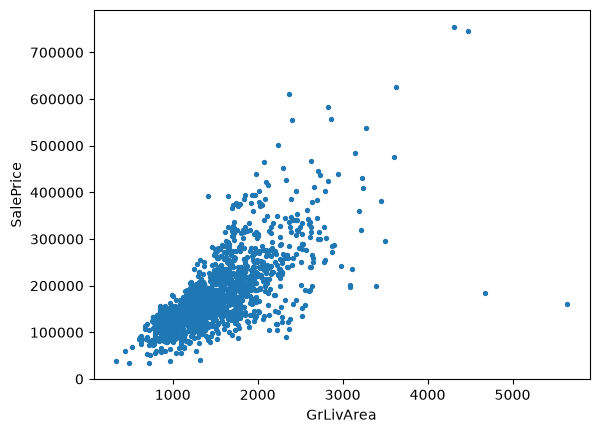

In [15]:
import matplotlib.pyplot as plt

plt.scatter(df["GrLivArea"], df["SalePrice"], s=8)
plt.xlabel("GrLivArea"); plt.ylabel("SalePrice")
plt.show()

In [16]:
big = df[df["GrLivArea"] > 4000]
big[["Id", "GrLivArea", "SalePrice", "OverallQual"]]

,Id,GrLivArea,SalePrice,OverallQual
523,524,4676,184750,10
691,692,4316,755000,10
1182,1183,4476,745000,10
1298,1299,5642,160000,10


In [17]:
out = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)
print(out.sum(), df.loc[out, "Id"].tolist())

2 [524, 1299]


**STAGE 4. EXPLORE: the target, then column vs target**

- QUESTION: What shape is the target, and which columns drive the price?
- CHECK: describe(), skew() and hist for SalePrice and log1p(SalePrice); corr() of every numeric column with SalePrice; corr() between feature pairs; groupby("Neighborhood"), groupby("OverallQual") and groupby("YrSold") with median(); counts of zeros.
- FINDING:
  * SalePrice is right-skewed: skew 1.88, mean 180,921 against median 163,000. After log1p the skew is 0.12 (mean 12.02, std 0.40).
  * Strongest signals: OverallQual (r=0.79) and GrLivArea (r=0.71), then GarageCars (0.64).
  * Redundant pairs (r above 0.8): GarageCars with GarageArea (0.88), YearBuilt with GarageYrBlt (0.83), GrLivArea with TotRmsAbvGrd (0.83), TotalBsmtSF with 1stFlrSF (0.82).
  * Location moves the median by a factor of 3.6 (MeadowV 88,000 to NridgHt 315,000, across 25 neighbourhoods).
  * Median price rises at every OverallQual step, by a factor and not a constant amount (50,150 at 1, 133,000 at 5, 432,390 at 10).
  * Year sold: the median is nearly flat (163,995 in 2006, 155,000 in 2010, about -5 %).
- DECISION: I will train on log1p(SalePrice) because the price is right-skewed and the log turns errors into percentages. The redundant pairs make linear weights unstable, so I keep all the columns and let Ridge (the penalty) handle them. The year sold barely moves the median, so it is not a strong feature.

- S4-1  SalePrice: mean 180,921, median 163,000, skew 1.88, max 755,000. After np.log1p: skew 0.12, mean ≈ 12.02, std ≈ 0.40.
- S4-2  Top numeric correlations with SalePrice (raw price): OverallQual (0.79), GrLivArea (0.71), GarageCars (0.64). The most negative is KitchenAbvGr (-0.14).
- S4-3  r(GarageCars, GarageArea) = 0.88; r(TotalBsmtSF, 1stFlrSF) = 0.82; r(GrLivArea, TotRmsAbvGrd) = 0.83. Two columns that say the same thing are called redundant (collinear), and they make linear weights unstable.
- S4-4  Median price: cheapest neighbourhood MeadowV (88,000), dearest NridgHt (315,000). Ratio = 3.6. There are 25 neighbourhoods.
- S4-5  Median price at OverallQual 1 = 50,150; at 5 = 133,000; at 10 = 432,390. It grows roughly by a constant factor. That is another reason to use the log.
- S4-6  Median price by YrSold: 2006 163,995; 2010 155,000. Conclusion: nearly flat, the sale year barely changes the price.
- S4-7  Most of the area columns (PoolArea, 3SsnPorch, MiscVal, ScreenPorch, LowQualFinSF, EnclosedPorch) are 0 for almost all houses (2ndFlrSF is 0 in 829 of 1,460, which marks one-storey houses). A column that is 0 in 99 percent of rows teaches a model very little, but I keep it because the few non-zero houses can still matter and trees can use them.

In [18]:
df["SalePrice"].describe()
print("skew:", df["SalePrice"].skew(), "| median", df["SalePrice"].median(), "| mean:", df["SalePrice"].mean())
print(df["SalePrice"].max())

skew: 1.8828757597682129 | median 163000.0 | mean: 180921.19589041095
755000


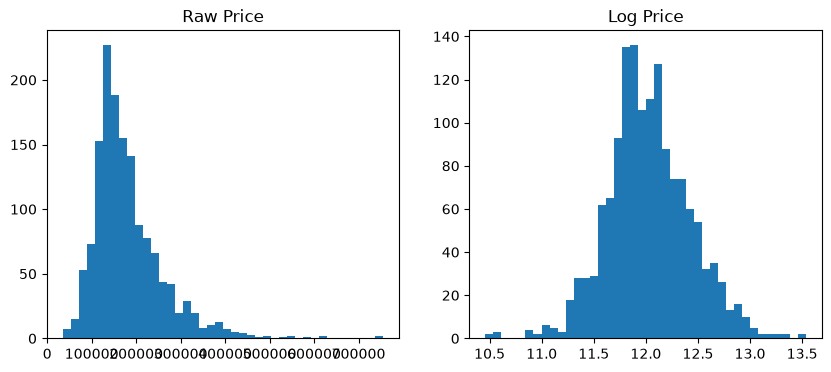

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(df["SalePrice"], bins=40)
ax[0].set_title("Raw Price")

ax[1].hist(np.log1p(df["SalePrice"]), bins=40)
ax[1].set_title("Log Price")

plt.show()


In [20]:
s = np.log1p(df["SalePrice"])
print("log skew:", s.skew(), "| mean:", s.mean(), "| std:", s.std())

log skew: 0.12134661989685333 | mean: 12.024057394918406 | std: 0.3994492733225068


In [21]:
corr = df.select_dtypes(include="number").corr()["SalePrice"].sort_values(ascending=False)
print(corr.head(9).round(2))
print(corr.tail(3).round(2))

SalePrice       1.00
OverallQual     0.79
GrLivArea       0.71
GarageCars      0.64
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
FullBath        0.56
TotRmsAbvGrd    0.53
Name: SalePrice, dtype: float64
MSSubClass      -0.08
EnclosedPorch   -0.13
KitchenAbvGr    -0.14
Name: SalePrice, dtype: float64


In [22]:
for a, b in [("GarageCars", "GarageArea"), ("TotalBsmtSF", "1stFlrSF"), ("GrLivArea", "TotRmsAbvGrd")]:
    print(a, b, round(df[a].corr(df[b]), 2))

GarageCars GarageArea 0.88
TotalBsmtSF 1stFlrSF 0.82
GrLivArea TotRmsAbvGrd 0.83


In [23]:
med = df.groupby("Neighborhood")["SalePrice"].median().sort_values()
print(med.head(1))
print(med.tail(1))
print("neighborhoods:", df["Neighborhood"].nunique())

Neighborhood
MeadowV    88000.0
Name: SalePrice, dtype: float64
Neighborhood
NridgHt    315000.0
Name: SalePrice, dtype: float64
neighborhoods: 25


OverallQual
1      50150.0
5     133000.0
10    432390.0
Name: SalePrice, dtype: float64


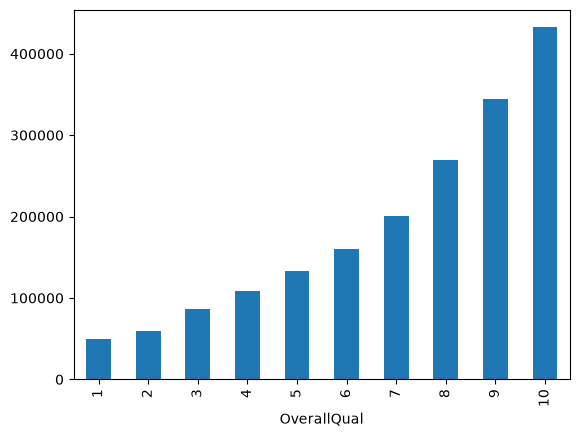

In [24]:
q = df.groupby("OverallQual")["SalePrice"].median()
print(q.loc[[1, 5, 10]])
q.plot(kind="bar");  plt.show()

In [25]:
df.groupby("YrSold")["SalePrice"].median()

YrSold
2006    163995.0
2007    167000.0
2008    164000.0
2009    162000.0
2010    155000.0
Name: SalePrice, dtype: float64

In [26]:
for c in ["PoolArea", "MiscVal", "3SsnPorch", "ScreenPorch", "LowQualFinSF", "EnclosedPorch", "2ndFlrSF"]:
    print(c, (df[c] > 0).sum())

PoolArea 7
MiscVal 52
3SsnPorch 24
ScreenPorch 116
LowQualFinSF 26
EnclosedPorch 208
2ndFlrSF 631


**STAGE 5. THE TARGET AND THE AVAILABILITY AUDIT**

- QUESTION: Which columns would I know at the moment someone asks for a valuation, and what is my target?
- CHECK: np.log1p / np.expm1 round trip; groupby("SaleCondition") and groupby("SaleType") with count and mean.
- FINDING: The target is y = log1p(SalePrice), and expm1 returns exactly the original prices. No column contains the price itself, so 0 columns truly leak it. Two columns, SaleType and SaleCondition, describe the sale event and are unavailable before a sale (Partial 272,292 against Normal 175,202 and Abnorml 146,527).
- DECISION: Features = all columns except Id and SalePrice for now. I intend to drop SaleType and SaleCondition and will confirm in Stage 8 (change A) that dropping costs nothing. Neighborhood stays (location drives price) with a fairness note.

| Column | Known when valuing? | Decision | Reason |
|---|---|---|---|
| Id | yes | drop | A row number, no information about the house |
| SalePrice | no | drop from X | It is the target; leaving it in would be real leakage |
| SaleType | no | intend to drop | Describes the sale, not the house; unknown before the sale |
| SaleCondition | no | intend to drop | Circumstances of the sale (Partial = unfinished new build); unknown before the sale |
| MoSold, YrSold | yes (today) | keep for now | The model has only seen 2006 to 2010 and the median is nearly flat, so little is lost; YrSold is needed for HouseAge in Stage 8 |
| Neighborhood | yes | keep | Location drives price. Fairness: neighbourhoods can stand in for protected groups, so a lender should not use it to refuse loans |

- S5-1  Target after the transform: y = np.log1p(SalePrice). To get dollars back I use np.expm1.
- S5-2  Columns that cannot be features: SalePrice (the target) and Id (no information).
- S5-3  SaleCondition mean price: Normal 175,202; Partial 272,292; Abnorml 146,527. My decision: drop, because it describes the circumstances of the sale, which are unknown at valuation time.
- S5-4  I will test BOTH ways in Stage 8 (keep vs drop SaleType and SaleCondition) and decide by comparing CV mean and std.
- S5-5  Neighborhood is allowed here because location predicts price, but a lender who used it to refuse loans could end up discriminating, because neighbourhoods can stand in for protected groups.
- S5-6  The number of columns that truly leak the price: 0.

In [27]:
y_log = np.log1p(df["SalePrice"])
print("skew:", round(y_log.skew(), 2))

back = np.expm1(y_log)
print("round trip exact:", np.allclose(back, df["SalePrice"]))

skew: 0.12
round trip exact: True


In [28]:
df.groupby("SaleCondition")["SalePrice"].agg(["count", "mean"]).round(0)

,count,mean
SaleCondition,,
Abnorml,101,146527.0
AdjLand,4,104125.0
Alloca,12,167377.0
Family,20,149600.0
Normal,1198,175202.0
Partial,125,272292.0


In [29]:
df.groupby("SaleType")["SalePrice"].agg(["count", "mean"]).round(0)

,count,mean
SaleType,,
COD,43,143973.0
CWD,4,210600.0
Con,2,269600.0
ConLD,9,138781.0
ConLI,5,200390.0
ConLw,5,143700.0
New,122,274945.0
Oth,3,119850.0
WD,1267,173402.0


**STAGE 6. STATELESS PREP, SPLIT, BASELINE**

- QUESTION: What may I do before the split, and what number must a real model beat?
- CHECK: astype, fillna, get_dummies; train_test_split; the outlier mask on the train part only; len(Xtr) / Xtr.shape[1]; DummyRegressor in 5-fold CV.
- FINDING: After the stateless prep X has 1,460 rows and 317 columns, and 3 columns still hold NaN (LotFrontage, MasVnrArea, GarageYrBlt). The split gives 1,168 train and 292 test rows. 2 outliers are in the train part and 0 in the test part, so the train part has 1,166 rows. Rows per column = 1,166 / 317 = 3.68. The baseline (predicting the mean) scores RMSE 0.3906 ± 0.0115 on the log price, almost equal to the std of y_train (0.3908), which means about 48 percent off.
- DECISION: The test part is sealed and has not been scored. The imputer and scaler go inside a Pipeline after the split. With only 3.68 rows per column I expect flexible models to overfit and Ridge to help. Any model must beat 0.39.

- S6-1  Learning steps that must come AFTER the split: SimpleImputer(strategy="median") and StandardScaler. Reason: they compute statistics (a median, a mean, a standard deviation) from the data, and computing them on the test rows would let the test rows leak into the model.
- S6-2  get_dummies before the split is allowed because it only lists the category names and learns no information from the prices.
- S6-3  After the prep, X has 1,460 rows and 317 columns; columns that still contain NaN: 3 (names: LotFrontage, MasVnrArea, GarageYrBlt).
- S6-4  train_test_split(X, y, test_size=0.2, random_state=42) gives train = 1,168 and test = 292. No stratify, because stratify is for classes in a classification target and a continuous price has no classes.
- S6-5  Outliers in the train part: 2; in the test part: 0. Train rows after removal: 1,166. Test rows untouched: 292.
- S6-6  Rows per column in the training part: 1,166 ÷ 317 = 3.68.
- S6-7  Baseline: DummyRegressor CV RMSE = 0.3906 ± 0.0115; std of y_train = 0.3908. Meaning in percent: about 48 percent off.
- S6-8  The test set has been opened 0 time(s) so far.

In [30]:
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_squared_error

In [31]:
y = np.log1p(df["SalePrice"].values)
X = df.drop(columns=["Id", "SalePrice"])

In [32]:
txt = X.select_dtypes(exclude="number").columns
X[txt] = X[txt].fillna("None")
print(X[txt].isna().sum().sum())

0


In [33]:
X["MSSubClass"] = X["MSSubClass"].astype(str)

In [34]:
X = pd.get_dummies(X, dtype=float)
print(X.shape)
print(list(X.columns[X.isna().any()]))

(1460, 317)
['LotFrontage', 'MasVnrArea', 'GarageYrBlt']


In [35]:
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(Xtr.shape, Xte.shape)

(1168, 317) (292, 317)


In [36]:
Xtr_all, ytr_all = Xtr, ytr
bad = (Xtr["GrLivArea"] > 4000) & (np.expm1(ytr) < 300000)
print("outliers in train:", bad.sum())

badte = (Xte["GrLivArea"] > 4000) & (np.expm1(yte) < 300000)
print("outliers in test:", badte.sum())

Xtr, ytr = Xtr[~bad], ytr[~bad.to_numpy()]
print(Xtr.shape, ytr.shape)

outliers in train: 2
outliers in test: 0
(1166, 317) (1166,)


In [37]:
print("rows per column:", round(len(Xtr) / Xtr.shape[1], 2))

rows per column: 3.68


In [38]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
s = -cross_val_score(DummyRegressor(strategy="mean"), Xtr, ytr, cv=kf, scoring="neg_root_mean_squared_error")
print(round(s.mean(), 4), round(s.std(), 4), "| std of ytr:", round(ytr.std(), 4))

0.3906 0.0115 | std of ytr: 0.3908


**STAGE 7. LINEAR MODELS AND RIDGE**

- QUESTION: Does regularisation fix the problem of 3.68 rows per column, and what is the number to beat in Stage 8?
- CHECK: LinearRegression and Ridge in one Pipeline (imputer, scaler, model), 5-fold CV on the same folds, an alpha loop, the same model with and without the 2 outliers, a hand-written CV loop, and train RMSE against CV RMSE.
- FINDING: LinearRegression scores 0.1447 ± 0.0174, with the outliers 0.1682 ± 0.0254. Ridge improves it steadily and is best at alpha 300 (0.1180 ± 0.0037, not at the edge of the list). With the outliers the same Ridge drops to about 0.141 ± 0.027, so two houses out of 1,168 make the std about 7 times larger. Train RMSE is 0.091 against CV 0.118 (gap about 0.027), a mild overfit.
- DECISION: Ridge, alpha 300, is the model to beat in Stage 8. Outliers stay out of the training part. The test part is still sealed (0 openings).

- S7-1  The order is SimpleImputer, then StandardScaler, then the model. The imputer is first because Ridge and LinearRegression cannot take NaN, and the scaler should compute its mean and std on complete columns.
- S7-2  KFold(n_splits=5, shuffle=True, random_state=42). The scoring name is "neg_root_mean_squared_error". scikit-learn returns it negative because it always treats a higher score as better, so an error is negated and I flip it back with a minus sign.
- S7-3  LinearRegression: CV RMSE = 0.1447 ± 0.0174 (clean) and 0.1682 ± 0.0254 (with the outliers).
- S7-4  Ridge table (clean train part):
        alpha   mean     std
          10    0.1333   0.0109
          30    0.1282   0.0076
         100    0.1218   0.0046
         300    0.1180   0.0037
        1000    0.1230   0.0046
        Best alpha = 300. The curve is U-shaped.
- S7-5  Best Ridge WITH the outliers: about 0.141 ± 0.027 (copy the exact printed numbers). The std is about 7 times bigger than without them. Two houses out of 1,168 did that.
- S7-6  Ridge train RMSE = 0.091; CV RMSE = 0.118; gap = 0.027.
- S7-7  Ridge needs scaling because the penalty charges every coefficient the same price, so without scaling it punishes small-unit columns (such as 0/1 dummies) much harder than big-unit columns. A forest does not need it because a split only compares values to a threshold, and rescaling does not change the order of the values.
- S7-8  My hand-written 5-fold loop gives mean 0.118 and std 0.0037. It does match cross_val_score.

In [39]:
def cv_rmse(model, X, y):
    s = -cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
    return s.mean(), s.std()

In [40]:
lin = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
    ("m", LinearRegression()),
])
print("clean:            ", cv_rmse(lin, Xtr, ytr))
print("with outliers:    ", cv_rmse(lin, Xtr_all, ytr_all))

clean:             (np.float64(0.14474067413664948), np.float64(0.01737584111102387))
with outliers:     (np.float64(0.16823607879079172), np.float64(0.025437105618195024))


In [41]:
results = []
for a in [10, 30, 100, 300, 1000]:
    pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("m", Ridge(alpha=a))
    ])
    m, sd = cv_rmse(pipe, Xtr, ytr)
    results.append((a, m, sd))

In [42]:
table = pd.DataFrame(results, columns=["alpha", "mean", "std"])
table.sort_values("mean")

,alpha,mean,std
3,300,0.118022,0.003663
2,100,0.121796,0.004591
4,1000,0.122969,0.004599
1,30,0.128153,0.007601
0,10,0.133320,0.010906


In [43]:
best = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
    ("m", Ridge(alpha=300))
])
print("clean :", cv_rmse(best, Xtr, ytr))
print("with outliers :", cv_rmse(best, Xtr_all, ytr_all))

clean : (np.float64(0.11802216029376075), np.float64(0.003662837959337905))
with outliers : (np.float64(0.14115683650485764), np.float64(0.027411440402970454))


In [44]:
scores = []
for tr_idx, va_idx in kf.split(Xtr):
    model = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("m", Ridge(alpha=300))
    ])
    model.fit(Xtr.iloc[tr_idx], ytr[tr_idx])
    pred = model.predict(Xtr.iloc[va_idx])
    scores.append(np.sqrt(mean_squared_error(ytr[va_idx], pred)))
print(round(np.mean(scores), 4), round(np.std(scores), 4))

0.118 0.0037


In [45]:
best.fit(Xtr, ytr)
train_rmse = np.sqrt(mean_squared_error(ytr, best.predict(Xtr)))
print("train:", round(train_rmse, 4), "| cv:", round(cv_rmse(best, Xtr, ytr)[0], 4))

train: 0.091 | cv: 0.118


**STAGE 8.  THE FOREST, THE OVERFITTING GAP, AND "ONE CHANGE AT A TIME"**
**STAGE 8. FOREST, GAP TABLE, ONE CHANGE AT A TIME**

- QUESTION: Does a forest beat Ridge, and does any single change to the features help?
- CHECK: RandomForestRegressor (300 trees) in a pipeline, 5-fold CV on the same folds, train RMSE against CV RMSE, then changes A, B, C and B+C on the best Ridge, each against the same reference.
- FINDING: The forest scores 0.1376 ± 0.0047, worse than Ridge (0.1180 ± 0.0037). Its gap is 0.086 against 0.027 for Ridge, so it memorises. None of the four changes differs from the reference by more than the larger std, so none is a real improvement.
- DECISION: Ridge stays the model to beat. Feature set A (drop SaleType and SaleCondition). The test part is still sealed.

| model | train | CV | gap |
|---|---|---|---|
| Ridge a=300 | 0.0910 | 0.1180 | 0.0270 |
| Forest 300 | 0.0515 | 0.1376 | 0.0861 |

DECISION: The forest is clearly more overfit and clearly worse; the Ridge family suits this data.

| change | columns | mean | std | diff | real? |
|---|---|---|---|---|---|
| reference | 317 | 0.1180 | 0.0037 | 0 | |
| A drop SaleType+SaleCondition | 302 | 0.1187 | 0.0050 | +0.0007 | no |
| B ordered quality columns | 277 | 0.1177 | 0.0041 | -0.0003 | no |
| C TotalSF and HouseAge | 319 | 0.1167 | 0.0039 | -0.0013 | no |
| B + C | 279 | 0.1164 | 0.0043 | -0.0016 | no |

DECISION: No change beats the larger std, so I keep the simplest feature set and use A for availability.

- S8-1  Forest: CV RMSE = 0.1376 ± 0.0047; train RMSE = 0.0515; gap = 0.0861. Ridge gap = 0.0270. So the forest is more overfit.
- S8-2  A regression forest's leaf predicts the mean (average) of the training prices in that leaf, so it can never predict a price higher than the biggest training price. (T6)
- S8-3  Reference (best Ridge): 0.1180 ± 0.0037. The table is above. Real by the T9 rule: none, because the best gain (0.0016) is smaller than the larger std (0.0043).
- S8-4  Column counts: base 317; after B 277 (the ten quality columns stop being one-hot); after C 319. B has fewer columns because ten text columns with 4 to 6 categories each (about 50 dummy columns) become one number column each.
- S8-5  My final feature set: A (drop SaleType and SaleCondition). Reasons: those two are not known before a sale (availability), dropping them costs only 0.0007 (inside the noise), and it removes 15 columns (simplicity).
- S8-6  The difference is 0.0196 (0.1376 - 0.1180), which is more than the larger std (0.0047), so the winner is Ridge.

In [46]:
rf = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("m", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))
])
rf_m, rf_sd = cv_rmse(rf, Xtr, ytr)
rf.fit(Xtr, ytr)
rf_train = np.sqrt(mean_squared_error(ytr, rf.predict(Xtr)))
print(round(rf_m, 4), round(rf_sd, 4), "| train:", round(rf_train, 4))

0.1376 0.0047 | train: 0.0515


In [47]:
best.fit(Xtr, ytr)
ridge_train = np.sqrt(mean_squared_error(ytr, best.predict(Xtr)))
ref_m, ref_sd = cv_rmse(best, Xtr, ytr)
gap = pd.DataFrame([("Ridge a=300", ridge_train, ref_m),
                    ("Forest 300", rf_train, rf_m)],
                    columns=["model", "train", "cv"])
gap["gap"] = gap["cv"] - gap["train"]
gap.round(4)

,model,train,cv,gap
0,Ridge a=300,0.0910,0.1180,0.0270
1,Forest 300,0.0515,0.1376,0.0861


In [48]:
def prep(df, ordinal=False, feats=False):
    X = df.drop(columns=["Id", "SalePrice"]).copy()
    X["MSSubClass"] = X["MSSubClass"].astype(str)
    txt = X.select_dtypes(exclude="number").columns
    X[txt] = X[txt].fillna("None")
    if ordinal:
        order = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
        for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                  "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]:
            X[c] = X[c].map(order).astype(float)
    if feats:
        X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
        X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
    return pd.get_dummies(X, dtype=float)

print(prep(df).shape)
print(prep(df).shape, prep(df, ordinal=True).shape, prep(df, feats=True).shape)

(1460, 317)
(1460, 317) (1460, 277) (1460, 319)


In [49]:
cols = [c for c in Xtr.columns if c.startswith(("SaleType", "SaleCondition"))]
XtrA = Xtr.drop(columns=cols)
print(len(cols), XtrA.shape[1])

15 302


In [50]:
XtrB = prep(df, ordinal=True).loc[Xtr.index]
XtrC = prep(df, feats=True).loc[Xtr.index]
XtrBC = prep(df, ordinal=True, feats=True).loc[Xtr.index]
print(XtrB.shape, XtrC.shape, XtrBC.shape)

(1166, 277) (1166, 319) (1166, 279)


In [51]:
rows = []
for name, Xv in {"A": XtrA, "B": XtrB, "C": XtrC, "B+C": XtrBC}.items():
    m, sd = cv_rmse(best, Xv, ytr)
    rows.append((name, Xv.shape[1], m, sd, m - ref_m,
                 abs(m - ref_m) > max(sd, ref_sd)))
pd.DataFrame(rows, columns=["change", "columns", "mean", "std", "diff", "real?"]).round(4)

,change,columns,mean,std,diff,real?
0,A,302,0.1187,0.0050,0.0007,False
1,B,277,0.1177,0.0041,-0.0004,False
2,C,319,0.1167,0.0039,-0.0013,False
3,B+C,279,0.1164,0.0043,-0.0016,False


**STAGE 9. XGBOOST: BOOSTING BY HAND, THEN THE LIBRARY**

- QUESTION: What is boosting, and does it beat Ridge on this data?
- CHECK: A 4-house boosting table by hand; default XGBRegressor and a hand-set one in 5-fold CV on the same folds; three one-knob tables; early stopping on an inner validation split; importances; the three models on the same validation rows.
- FINDING: Default XGBoost memorises (train 0.0062, CV 0.1416 ± 0.0071). With small steps and shallow trees (600 trees, learning rate 0.03, depth 3) CV falls to 0.1163 ± 0.0031, a little better than Ridge (0.1187 ± 0.0050 on the same columns), but the gain is smaller than the larger std. Early stopping picks a few hundred trees by itself (587 here) and the curve is flat afterwards.
- DECISION: XGBoost with the hand-set values is the best candidate, but by the T9 rule Ridge keeps its place unless the gain is larger than the noise. Stage 11 decides.

**9a. Boosting by hand** (prices in thousands: A 100, B 150, C 200, D 350)
- Round 0: F0 = mean = 200. Residuals: A -100, B -50, C 0, D 150. SSE = 35,000.
- Round 1 (split {A,B,C} against {D}): leaves -50 and 150. With learning_rate 0.5: F1 = A 175, B 175, C 175, D 275. Residuals: A -75, B -25, C 25, D 75. SSE = 12,500.
- Round 2 (split {A,B} against {C,D}): leaves -50 and 50. F2 = A 150, B 150, C 200, D 300. Residuals: A -50, B 0, C 0, D 50. SSE = 5,000.
- SSE fell 35,000 -> 12,500 -> 5,000, because each tree fits what the earlier trees missed. With a learning rate of 1.0 the SSE after round 1 is already 5,000: every tree is trusted completely, which is fast but jumpy on noisy data. A small rate takes smaller, safer steps, so it needs more rounds.

**Gap table**

| model | columns | train | CV | gap |
|---|---|---|---|---|
| Ridge a=300 | 317 | 0.0910 | 0.1180 | 0.0270 |
| Forest 300 | 317 | 0.0515 | 0.1376 | 0.0861 |
| XGBoost default | 302 | 0.0062 | 0.1416 | 0.1354 |
| XGBoost hand-set | 302 | 0.0652 | 0.1163 | 0.0511 |

**Knob tables** (CV mean ± std, one knob at a time from the hand-set model)

| n_estimators | mean ± std | learning_rate | mean ± std | max_depth | mean ± std |
|---|---|---|---|---|---|
| 100 | 0.1445 ± 0.0044 | 0.01 | 0.1237 ± 0.0036 | 2 | 0.1183 ± 0.0029 |
| 300 | 0.1196 ± 0.0031 | 0.03 | 0.1163 ± 0.0031 | 3 | 0.1163 ± 0.0031 |
| 600 | 0.1163 ± 0.0031 | 0.1 | 0.1166 ± 0.0017 | 4 | 0.1179 ± 0.0036 |
| 1000 | 0.1153 ± 0.0030 | 0.3 | 0.1294 ± 0.0061 | 6 | 0.1224 ± 0.0050 |

DECISION: My XGBoost settings are n_estimators=600, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.5, random_state=42, because (1) the trees-and-rate tables show 600 trees at rate 0.03 is where the gain stops being larger than the std, (2) depth 2, 3 and 4 are within the noise so I take the middle and simplest, and (3) the small gap (0.051 against 0.135 for the defaults) shows the overfitting is under control.

- S9-1  Forest: trees are built independently and then averaged; boosting: trees are built one after another and each one fits the residuals (errors) of the trees so far.
- S9-2  Forest cures variance by averaging; boosting cures bias by adding small corrections.
- S9-3  learning_rate multiplies each tree's contribution (its leaf values). A small rate needs more trees.
- S9-4  Default XGBRegressor: train RMSE = 0.0062; CV RMSE = 0.1416 ± 0.0071. Gap = 0.1354. Verdict: it memorises the training houses (train error about 23 times smaller than CV).
- S9-5  Hand-set model: CV = 0.1163 ± 0.0031; train RMSE = 0.0652.
- S9-6  n_estimators: 100: 0.1445, 300: 0.1196, 600: 0.1163, 1000: 0.1153. learning_rate: 0.01: 0.1237, 0.03: 0.1163, 0.1: 0.1166, 0.3: 0.1294. max_depth: 2: 0.1183, 3: 0.1163, 4: 0.1179, 6: 0.1224. The knob that matters most: n_estimators (0.1445 to 0.1153). A knob where the change is smaller than the std: max_depth between 2, 3 and 4 (and n_estimators from 600 to 1000).
- S9-7  XGBoost reads NaN by itself, so the imputer is not needed. With and without the imputer the CV is about the same.
- S9-8  Early stopping: n_estimators=3000 asked, 638 trees were actually built, best_iteration = 587, best validation RMSE = 0.1200. RMSE at 100 trees = 0.1397; at 300 = 0.1217; at the last tree = 0.1202. This is the same idea as Day 17 early stopping with patience = 50.
- S9-9  XGBoost top importance: ExterQual_TA (0.095), FireplaceQu_None (0.093), OverallQual (0.083). Forest top importance: OverallQual (0.518), GrLivArea (0.113), GarageArea (0.042). They differ because many one-hot and quality columns carry the same signal; the forest builds independent trees that nearly all start with OverallQual, while boosting spreads the leftover credit over many correlated indicators. Importance is not cause and effect.
- S9-10 Same inner validation rows: Ridge 0.1214; forest 0.1337; XGBoost 0.1206. Differences smaller than about 0.005 are noise.
- S9-11 reg_lambda in XGBoost is the same idea as alpha in Ridge and weight_decay in AdamW.

In [52]:
import xgboost as xgb
print(xgb.__version__)

3.4.1


In [53]:
Xf = XtrA

In [54]:
xg0 = xgb.XGBRegressor(random_state=42, n_jobs=-1)
x0_m, x0_sd = cv_rmse(xg0, Xf, ytr)
xg0.fit(Xf, ytr)
x0_train = np.sqrt(mean_squared_error(ytr, xg0.predict(Xf)))
print(round(x0_m, 4), round(x0_sd, 4), "| train:", round(x0_train, 4))

0.1416 0.0071 | train: 0.0062


In [55]:
xg1 = xgb.XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.5, random_state=42, n_jobs=-1)
x1_m, x1_sd = cv_rmse(xg1, Xf, ytr)
xg1.fit(Xf, ytr)
x1_train = np.sqrt(mean_squared_error(ytr, xg1.predict(Xf)))

xg1_imp = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("m", xg1)
])
print(round(x1_m, 4), round(x1_sd, 4), round(x1_train, 4), cv_rmse(xg1_imp, Xf, ytr))

0.1167 0.0031 0.0647 (np.float64(0.1157720813172242), np.float64(0.0031371031090424244))


In [56]:
def mk(**kw):
    p = dict(n_estimators=600, learning_rate=0.03, max_depth=3, subsample=0.8,
             colsample_bytree=0.5, random_state=42, n_jobs=-1)
    p.update(kw)
    return xgb.XGBRegressor(**p)

In [57]:
tab_n, tab_lr, tab_d = [], [], []
for n in [100, 300, 600, 1000]:
    m, sd = cv_rmse(mk(n_estimators=n), Xf, ytr); tab_n.append((n, m, sd))

for lr in [0.01, 0.03, 0.1, 0.3]:
    m, sd = cv_rmse(mk(learning_rate=lr), Xf, ytr); tab_lr.append((lr, m, sd))

for d in [2, 3, 4, 5, 6]:
    m, sd = cv_rmse(mk(max_depth=d), Xf, ytr); tab_d.append((d, m, sd))

for t in (tab_n, tab_lr, tab_d):
    print(pd.DataFrame(t, columns=["value", "mean", "std"]).round(4), "\n")

   value    mean     std
0    100  0.1450  0.0043
1    300  0.1195  0.0028
2    600  0.1167  0.0031
3   1000  0.1159  0.0035 

   value    mean     std
0   0.01  0.1233  0.0034
1   0.03  0.1167  0.0031
2   0.10  0.1182  0.0029
3   0.30  0.1287  0.0040 

   value    mean     std
0      2  0.1178  0.0032
1      3  0.1167  0.0031
2      4  0.1173  0.0029
3      5  0.1206  0.0032
4      6  0.1221  0.0026 



In [58]:
Xa, Xv, ya, yv = train_test_split(
    Xf, ytr, test_size=0.2, random_state=42
)
print(Xa.shape, Xv.shape)

(932, 302) (234, 302)


In [59]:
es = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=3, subsample=0.8,
                      colsample_bytree=0.5, random_state=42, early_stopping_rounds=50)
es.fit(Xa, ya, eval_set=[(Xv, yv)], verbose=False)
curve = es.evals_result()["validation_0"]["rmse"]
print(len(curve), es.best_iteration, round(es.best_score, 4))
print(round(curve[99], 4), round(curve[299], 4), round(curve[-1], 4))

638 587 0.12
0.1397 0.1217 0.1202


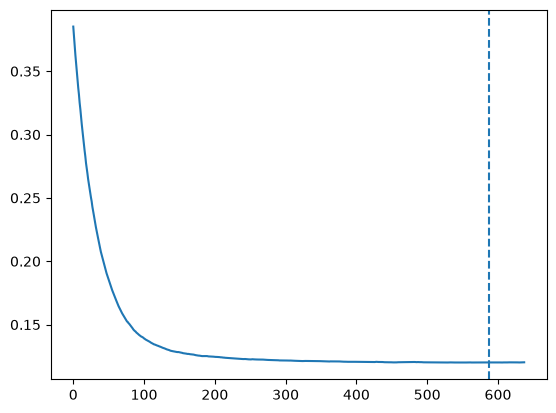

In [60]:
plt.plot(curve); plt.axvline(es.best_iteration, linestyle="--"); plt.show()

In [61]:
print(pd.Series(es.feature_importances_, index=Xa.columns).sort_values(ascending=False).head(8).round(3))
imp = SimpleImputer(strategy="median").fit(Xa)
rf_i = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_i.fit(imp.transform(Xa), ya)
print(pd.Series(rf_i.feature_importances_, index=Xa.columns).sort_values(ascending=False).head(6).round(3))

ExterQual_TA        0.095
FireplaceQu_None    0.093
OverallQual         0.083
KitchenQual_TA      0.052
GarageCars          0.051
BsmtQual_Ex         0.034
GrLivArea           0.034
YearBuilt           0.031
dtype: float32
OverallQual    0.518
GrLivArea      0.113
GarageArea     0.042
BsmtFinSF1     0.034
TotalBsmtSF    0.030
YearBuilt      0.026
dtype: float64


In [62]:
imp2 = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
    ("m", Ridge(alpha=300))
])
frs = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("m", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))
])

for name, model in [("Ridge", imp2), ("Forest", frs), ("XGBoost", mk())]:
    model.fit(Xa, ya)
    print(name, round(np.sqrt(mean_squared_error(yv, model.predict(Xv))), 4))

Ridge 0.1214
Forest 0.1337
XGBoost 0.1201


**STAGE 11. CHOOSE, TEST ONCE, ERRORS, LIMITS**

- QUESTION: How wrong will the tool be on houses it has never seen?
- CHECK: Final CV table for Ridge, forest and XGBoost on the same 302 columns and the same folds; the T9 rule applied before the test part was opened; Ridge refit on all 1,166 clean training rows; the test part opened once; dollar metrics; the five biggest misses; error by OverallQual; the most expensive test house.
- FINDING: Test RMSE on the log price is 0.1278 (CV was 0.1187 ± 0.0050, a difference of 0.009, about 1.8 stds), against a baseline of 0.4332; R2 is 0.912. In dollars the MAE is 15,230 and the RMSE 23,134, the median error is 5.5 percent and 9.6 percent of houses are more than 20 percent off. Four of the five biggest misses are Partial sales and dollar error grows with quality (6,600 at quality 3 against 45,656 at quality 9).
- DECISION: Ridge (alpha 300) is the model, because XGBoost's CV gain (0.0024) is smaller than the larger std (0.0050). Use it as a first estimate, not as a valuation.

- S11-1  Final table (CV, clean train part): Ridge 0.1187 ± 0.0050; Forest about 0.137 ± 0.005 (copy your printed numbers); XGBoost 0.1163 ± 0.0031. Winner by the T9 rule: Ridge, because the difference (0.0024) is smaller than the larger std (0.0050).
- S11-2  I refit on 1,166 rows and opened the test part 1 time.
- S11-3  Test: RMSE_log = 0.1278; CV = 0.1187 ± 0.0050; difference = 0.0091, which is about 1.8 stds. Baseline on the test part: 0.4332.
- S11-4  Dollars: MAE = 15,230; RMSE = 23,134; median percentage error = 5.5 percent; share more than 20 percent off = 9.6 percent; R2 (log scale) = 0.912. The RMSE is bigger than the MAE by about 7,900 because squaring makes a few large misses (over 100,000 dollars) count much more.
- S11-5  Five biggest misses: Id 899 (NridgHt, RL, quality 9, Partial, price 611,657, predicted 486,052); Id 775 (NridgHt, RL, 8, Partial, 395,000, 273,747); Id 219 (Crawfor, RL, 7, Normal, 311,500, 225,031); Id 589 (ClearCr, RL, 5, Partial, 143,000, 227,425); Id 582 (NridgHt, RL, 8, Partial, 253,293, 336,612). In common: four of the five are Partial sales, three are in NridgHt, and all are residential (RL) houses.
- S11-6  Mean absolute dollar error: lowest reliable group OverallQual 3 = 6,600; highest group OverallQual 9 = 45,656. Reason: the same percentage error costs more dollars on an expensive house, and the top groups hold very few houses.
- S11-7  My three limits: (1) one city and about four years of sales, so it will not carry to another market or time; (2) only 292 test houses, so the 9.6 percent over 20 percent off rests on about 28 houses; (3) rare and unusual houses (Partial sales, the most expensive) are the worst misses, OverallQual is a human rating, and the model cannot know things like the roof condition. It also lacks SaleCondition by design.
- S11-8  Fairness: Neighborhood and price can encode who lives where, so using the model to set prices or decide on loans could repeat old patterns unless it is checked group by group.
- S11-9  Use it as a first estimate to screen and rank houses, not as a final valuation or an offer price.
- S11-10 If I had one more day I would average Ridge and XGBoost (tied in CV, different mistakes) and log-transform the very skewed area columns, then re-check on the same folds.

Model card:
1. Data: 1,460 house sales, split 80/20 (1,166 clean train rows, 292 test rows), two outliers removed from the training part only.
2. Target: log of SalePrice, reported back as percent and dollars.
3. Features: 302 columns (text filled with "None", one-hot encoded, SaleType and SaleCondition dropped).
4. Model: Ridge (alpha 300) in a Pipeline with a median imputer and a StandardScaler.
5. Test score: RMSE 0.1278 on the log price, R2 0.912, typical error 5.5 percent, MAE 15,230 dollars.
6. Limits: one city and a few years, 292 test houses, weak on Partial sales and the most expensive houses.

In [63]:
ridge_m, ridge_sd = cv_rmse(best, Xf, ytr)
rf_m2,   rf_sd2   = cv_rmse(rf,   Xf, ytr)
xg_m,    xg_sd    = cv_rmse(mk(), Xf, ytr)
final_cv = pd.DataFrame([("Ridge",   ridge_m, ridge_sd),
                         ("Forest",  rf_m2,   rf_sd2),
                         ("XGBoost", xg_m,    xg_sd)], columns=["model", "mean", "std"])
print(final_cv.round(4))

     model    mean     std
0    Ridge  0.1187  0.0050
1   Forest  0.1381  0.0049
2  XGBoost  0.1167  0.0031


In [67]:
from numpy import hypot
print("XGBoost replaces Ridge?", (ridge_m - xg_m) > max(ridge_sd, xg_sd))
print("Forest replaces Ridge?",  (ridge_m - rf_m2) > max(ridge_sd, rf_sd2))

XGBoost replaces Ridge? False
Forest replaces Ridge? False


In [68]:
Xte_f = Xte[Xf.columns]
final = best
final.fit(Xf, ytr)
print(len(Xf), Xte_f.shape)

1166 (292, 302)


In [70]:
p_log = final.predict(Xte_f)
rmse_log = np.sqrt(mean_squared_error(yte, p_log))
print("RMSE_log: ", round(rmse_log, 4), "| R2: ", round(r2_score(yte, p_log), 3))
base = DummyRegressor().fit(Xf, ytr)
print("baseline on the test part:", round(np.sqrt(mean_squared_error(yte, base.predict(Xte_f))), 4))

RMSE_log:  0.1278 | R2:  0.912
baseline on the test part: 0.4332


In [72]:
p_usd = np.expm1(p_log)
y_usd = np.expm1(yte)
print("MAE        :", round(mean_absolute_error(y_usd, p_usd)))
print("RMSE       :", round(np.sqrt(mean_squared_error(y_usd, p_usd))))
print("median %err:", round(np.median(np.abs(p_usd / y_usd - 1)) * 100, 1))
print("share >20% :", round((np.abs(p_usd / y_usd - 1) > 0.2).mean() * 100, 1))

MAE        : 15230
RMSE       : 23134
median %err: 5.5
share >20% : 9.6


In [74]:
rep = df.loc[Xte.index, ["Id", "Neighborhood", "MSZoning", "OverallQual",
                         "SaleCondition", "SalePrice"]].copy()
rep["pred"] = p_usd.round(0)
rep["abs_err"] = (rep["pred"] - rep["SalePrice"]).abs()
rep.sort_values("abs_err", ascending=False).head(5)

,Id,Neighborhood,MSZoning,OverallQual,SaleCondition,SalePrice,pred,abs_err
898,899,NridgHt,RL,9,Partial,611657,486052.0,125605.0
774,775,NridgHt,RL,8,Partial,395000,273747.0,121253.0
218,219,Crawfor,RL,7,Normal,311500,225031.0,86469.0
588,589,ClearCr,RL,5,Partial,143000,227425.0,84425.0
581,582,NridgHt,RL,8,Partial,253293,336612.0,83319.0


In [75]:
rep.groupby("OverallQual")["abs_err"].mean().round(0)

OverallQual
2     19768.0
3      6600.0
4     13827.0
5     10172.0
6     11098.0
7     17869.0
8     24532.0
9     45656.0
10    34090.0
Name: abs_err, dtype: float64

In [76]:
rep[rep["Id"] == 692]

,Id,Neighborhood,MSZoning,OverallQual,SaleCondition,SalePrice,pred,abs_err
691,692,NoRidge,RL,10,Normal,755000,741866.0,13134.0
